In [1]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

print("GPU Available:")
print(tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
GPU Available:
[]


# Import All Libraries

In [8]:
import tensorflow as tf

# Keras
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import models

# CIFAR-10 dataset
from tensorflow.keras.datasets import cifar10

# CNN layers
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    AveragePooling2D,
    GlobalAveragePooling2D,
    Flatten,
    Dense,
    Input,
    BatchNormalization,
    Activation,
    Add
)

# Data augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import Sequential

# Callbacks
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

# Transfer Learning
from tensorflow.keras.applications import MobileNetV2

# Optimizer
from tensorflow.keras.optimizers import Adam

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import random

# Print TensorFlow version
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Load the CIFAR-10 Dataset

In [9]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

## Train/Test the dataset images and labels shape

In [10]:
print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)


In [11]:
print("Test images shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

Test images shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)


## Data types

In [12]:
print("Image data type:", X_train.dtype)
print("Label data type:", y_train.dtype)

Image data type: uint8
Label data type: uint8


## Unique class labels and number

In [13]:
print("Unique labels:", sorted(set(y_train.flatten())))
print("Number of classes:", len(set(y_train.flatten())))

Unique labels: [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9)]
Number of classes: 10


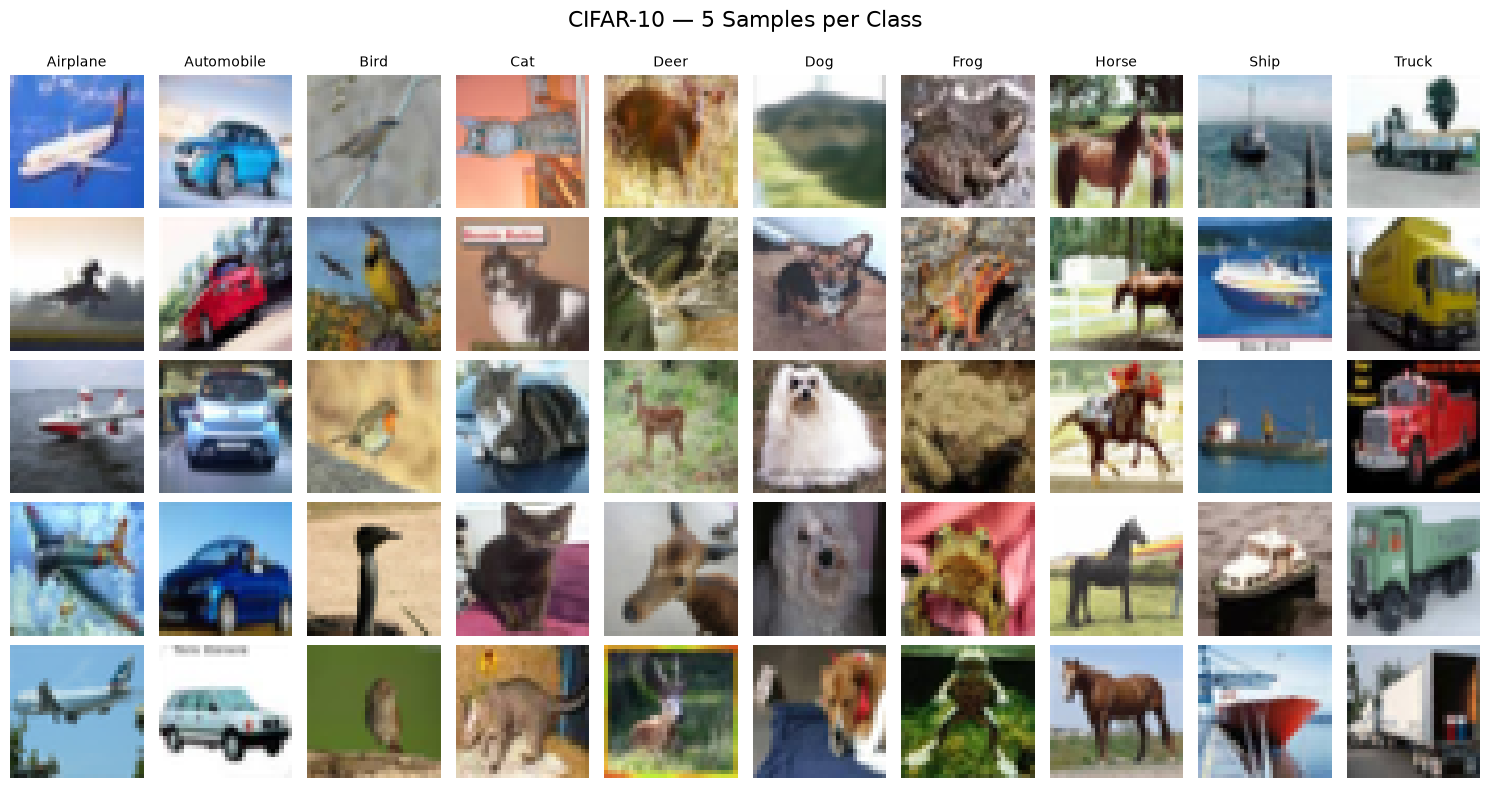

In [14]:
# Import required libraries
import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 class names
class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

# Create a 5 × 10 grid
fig, axes = plt.subplots(5, 10, figsize=(15, 8))

# Set the main title of the figure
fig.suptitle("CIFAR-10 — 5 Samples per Class", fontsize=16)

# Loop through each class
for class_id in range(10):

    # Find all image indexes belonging to this class
    class_indexes = np.where(y_train.flatten() == class_id)[0]

    # Select 5 random images from this class
    selected_indexes = np.random.choice(class_indexes, 5, replace=False)

    # Loop through the 5 selected images
    for row in range(5):

        # Get the image index
        image_index = selected_indexes[row]

        # Display the image
        axes[row, class_id].imshow(X_train[image_index])

        # Remove axis ticks
        axes[row, class_id].axis("off")

        # Add class name at the top of each column
        if row == 0:
            axes[row, class_id].set_title(class_names[class_id], fontsize=10)

# Adjust spacing
plt.tight_layout()

# Keep space for the main title
plt.subplots_adjust(top=0.90)

# Display the figure
plt.show()

## Observation

The CIFAR-10 dataset contains 10 different image classes, and the 5×10 grid shows five sample images from each class. Some classes are visually similar and may be difficult for the CNN to distinguish. In particular, **Cat vs Dog** can be difficult because both contain similar shapes and textures. **Automobile vs Truck** can also be challenging because both are vehicle classes with similar visual features. These visually similar class pairs are expected to produce some of the hardest classification errors for the CNN.

## Check pixel values before normalisation

In [15]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

print("Data type:", X_train.dtype)

Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8


## Histogram before normalisation

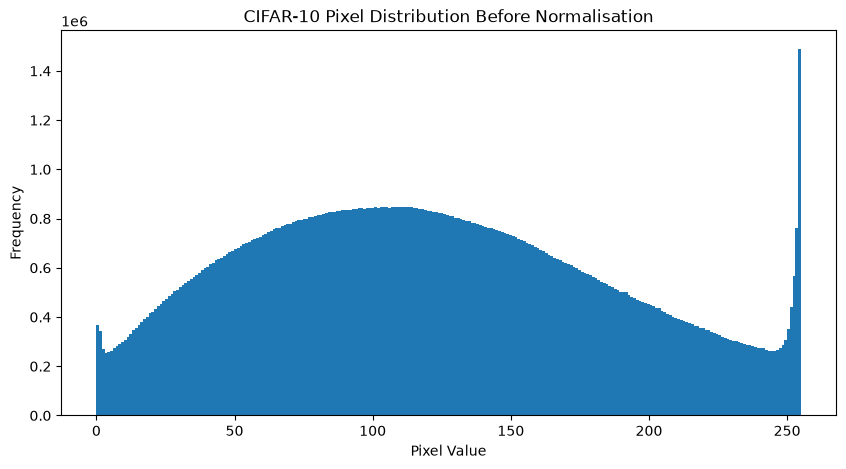

In [16]:
pixels_before = X_train.flatten()

plt.figure(figsize=(10, 5))
plt.hist(pixels_before, bins=256, range=(0, 255))

plt.title("CIFAR-10 Pixel Distribution Before Normalisation")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.show()

## Normalise the training and test images

In [17]:
# Convert training images to float32 and normalise to 0-1
X_train = X_train.astype('float32') / 255.0

# Convert test images to float32 and normalise to 0-1
X_test = X_test.astype('float32') / 255.0

## Check values after normalisation

In [18]:
print("Minimum value after normalisation:", X_train.min())
print("Maximum value after normalisation:", X_train.max())

print("Data type after normalisation:", X_train.dtype)

Minimum value after normalisation: 0.0
Maximum value after normalisation: 1.0
Data type after normalisation: float32


## Histogram after normalisation

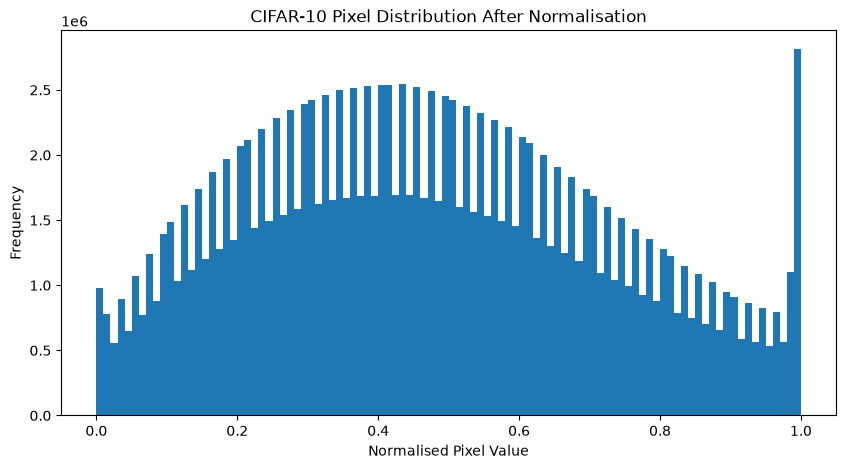

In [19]:
pixels_after = X_train.flatten()

plt.figure(figsize=(10, 5))

plt.hist(pixels_after, bins=100, range=(0, 1))
plt.title("CIFAR-10 Pixel Distribution After Normalisation")
plt.xlabel("Normalised Pixel Value")
plt.ylabel("Frequency")
plt.show()

## Observation

Before normalisation, CIFAR-10 pixel values range from 0 to 255. We normalise the images by converting them to `float32` and dividing by 255.0, which changes the range to [0, 1].

Normalisation is important because gradient descent generally converges faster when input values are on a small and consistent scale. Large raw pixel values, up to 255, can produce proportionally large initial weight updates and may make early training less stable. Scaling the input values to [0, 1] helps the CNN train more smoothly and efficiently.

# A1.4 One-Hot Encode Labels
## One-hot encode training labels

In [20]:
y_train_ohe = keras.utils.to_categorical(y_train, 10)

print("Shape of y_train_ohe:", y_train_ohe.shape)

Shape of y_train_ohe: (50000, 10)


In [21]:
y_test_ohe = keras.utils.to_categorical(y_test, 10)

print("Shape of y_test_ohe:", y_test_ohe.shape)

Shape of y_test_ohe: (10000, 10)


In [22]:
# Print the original label
print("Original label:", y_train[0][0])

# Print the one-hot encoded label
print("One-hot label:", y_train_ohe[0])

Original label: 6
One-hot label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


# A1.5 CNN vs ANN for Image Classification

### ANN (MLP)

An Artificial Neural Network (ANN), also called a Multi-Layer Perceptron (MLP), usually flattens an image into a 1D vector before passing it to the network.

For example, a 32 × 32 image becomes a vector containing 1,024 pixels per channel. This flattening loses the spatial relationships between neighboring pixels. The ANN does not directly know which pixels are next to each other in the original image.

### CNN

A Convolutional Neural Network (CNN) works directly with the 2D structure of an image. It uses a small learnable filter, also called a kernel, that slides across the image.

The same filter is used at different spatial positions, allowing it to detect local patterns such as edges, textures, and shapes regardless of where they appear in the image. This property is called **translation invariance**.

### Number of Parameters

CNNs usually require far fewer parameters than an equivalent MLP because the same filter weights are shared across all spatial positions.

For example, a 3 × 3 filter contains only **9 weights**. For a 32 × 32 image, the same 9 weights are reused across all 30 × 30 valid positions.

In comparison, an MLP would use independent weights for each input position when learning the same spatial coverage. A 32 × 32 image has **1,024 input positions**, so the number of independent weights can be much larger.

### Conclusion

CNNs are generally more suitable for image classification because they preserve spatial information, detect local patterns, use shared weights, and require fewer parameters than an equivalent MLP.

# A2.1 Manual Convolution Demo
## Extract Image and Convert to Grayscale

Grayscale image shape: (32, 32)


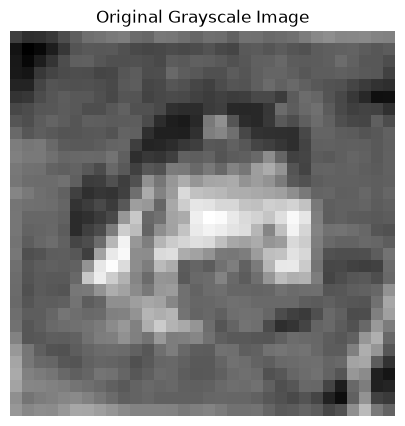

In [23]:
image = X_train[0]

gray = np.mean(image, axis=2)
print("Grayscale image shape:", gray.shape)

plt.figure(figsize=(5, 5))
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

## Define 3×3 Edge Detection Kernel

In [24]:
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Display the kernel
print("3 × 3 Edge Detection Kernel:")
print(kernel)

3 × 3 Edge Detection Kernel:
[[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]


## Apply Manual Convolution

In [25]:
from scipy.signal import convolve2d

# mode="valid" means no padding is added
convolved = convolve2d(gray, kernel, mode="valid")

print("Convolved output shape:", convolved.shape)

Convolved output shape: (30, 30)


## Display Original and Convolved Image

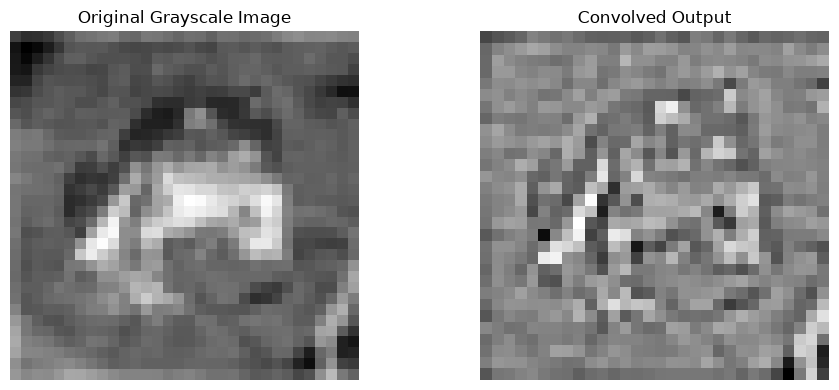

In [26]:
plt.figure(figsize=(10, 4))

# Display original grayscale image
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(convolved, cmap="gray")
plt.title("Convolved Output")
plt.axis("off")

plt.tight_layout()
plt.show()

# A2.2 Padding: VALID vs SAME
### Select a Test Image

Original image shape: (32, 32, 3)


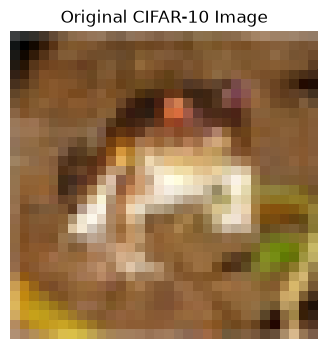

In [27]:
test_image = X_train[0]

print("Original image shape:", test_image.shape)

plt.figure(figsize=(4, 4))
plt.imshow(test_image)
plt.title("Original CIFAR-10 Image")
plt.axis("off")
plt.show()

## VALID Padding

In [28]:
model_valid = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, 3, padding="valid")
])

valid_output_shape = model_valid.output_shape

print("VALID padding output shape:", valid_output_shape)

VALID padding output shape: (None, 30, 30, 8)


## SAME Padding

In [29]:
model_same = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, 3, padding="same")
])

same_output_shape = model_same.output_shape

print("SAME padding output shape:", same_output_shape)

SAME padding output shape: (None, 32, 32, 8)


## Compare Output Sizes

In [30]:
print("VALID spatial size:", valid_output_shape[1:3])

print("SAME spatial size:", same_output_shape[1:3])

VALID spatial size: (30, 30)
SAME spatial size: (32, 32)


## Display Zero-Padded Image

Original shape: (32, 32, 3)
Padded shape: (34, 34, 3)


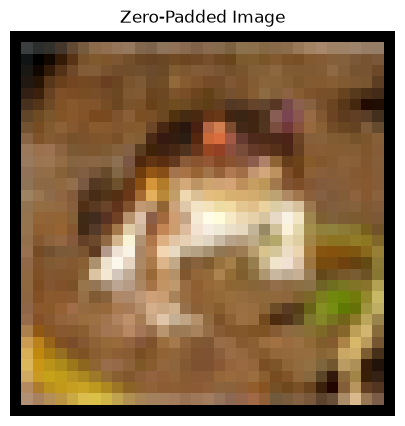

In [31]:
padded_image = np.pad(
    test_image,
    pad_width=((1, 1), (1, 1), (0, 0)),
    mode="constant",
    constant_values=0
)

print("Original shape:", test_image.shape)
print("Padded shape:", padded_image.shape)
plt.figure(figsize=(5, 5))
plt.imshow(padded_image)
plt.title("Zero-Padded Image")
plt.axis("off")
plt.show()

## Observation

`VALID` padding does not add zeros to the image, so the spatial dimensions become smaller after convolution.

`SAME` padding adds zero padding around the border and keeps the spatial dimensions unchanged when the stride is 1.

SAME padding is used in most CNN architectures because it allows many convolutional layers to be stacked without shrinking the spatial dimensions too quickly.

In this example:

| Padding | Input | Kernel | Stride | Output Spatial Size |
|---------|-------|--------|--------|---------------------|
| VALID | 32×32 | 3×3 | 1 | 30×30 |
| SAME | 32×32 | 3×3 | 1 | 32×32 |

# A2.3 Strides Effect
## Stride = 1

In [32]:
model_stride_1 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        filters=8,
        kernel_size=3,
        strides=1,
        padding="valid"
    )
])

print("Stride = 1 output shape:", model_stride_1.output_shape)

Stride = 1 output shape: (None, 30, 30, 8)


## Stride = 2

In [33]:
model_stride_2 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        filters=8,
        kernel_size=3,
        strides=2,
        padding="same"
    )
])
print("Stride = 2 output shape:", model_stride_2.output_shape)

Stride = 2 output shape: (None, 16, 16, 8)


## Compare Both

In [34]:
print("Stride = 1 spatial size:", model_stride_1.output_shape[1:3])

print("Stride = 2 spatial size:", model_stride_2.output_shape[1:3])

Stride = 1 spatial size: (30, 30)
Stride = 2 spatial size: (16, 16)


# Observation

**Stride** controls how many pixels the convolution filter moves at each step.

With `stride=1`, the filter moves one pixel at a time. This produces a dense feature map and preserves more spatial information.

With `stride=2`, the filter moves two pixels at a time. This reduces the spatial dimensions approximately by 2× and therefore performs downsampling.

For our example:

| Stride | Padding | Input | Kernel | Output |
|--------|---------|-------|--------|--------|
| 1 | VALID | 32×32 | 3×3 | 30×30 |
| 2 | SAME | 32×32 | 3×3 | 16×16 |

A stride of 2 can be used as an alternative to pooling for reducing spatial dimensions. Unlike fixed pooling operations, the convolution filters are **learnable**, so the network learns the features used during downsampling.

YOLOv8 uses **strided convolutions** for downsampling instead of traditional max-pooling layers.

# A2.4 Build and Visualise Feature Maps
## Build Conv2D Model

In [35]:
model_vis = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    )
])

model_vis.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

## Pass One Image Through the Model

In [36]:
one_image = X_train[0]
one_image_batch = np.expand_dims(one_image, axis=0)

feature_maps = model_vis(one_image_batch)
feature_maps = feature_maps.numpy()

print("Feature maps shape:", feature_maps.shape)

Feature maps shape: (1, 32, 32, 16)


## Remove Batch Dimension

In [37]:
feature_maps = feature_maps[0]

print("Feature maps after removing batch dimension:", feature_maps.shape)

Feature maps after removing batch dimension: (32, 32, 16)


## Display All 16 Feature Maps

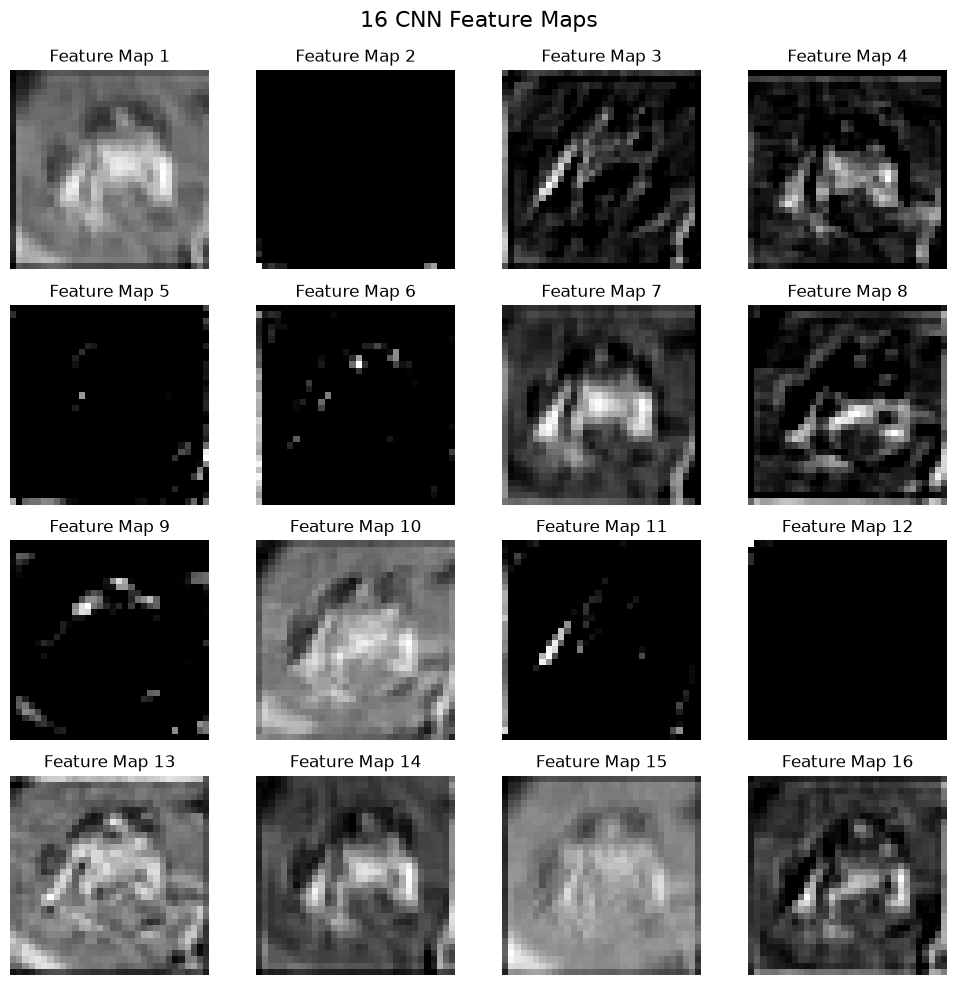

In [38]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("16 CNN Feature Maps", fontsize=16)

for i in range(16):

    # Find the correct subplot position
    row = i // 4
    col = i % 4

    axes[row, col].imshow(feature_maps[:, :, i], cmap="gray")
    axes[row, col].set_title(f"Feature Map {i + 1}")

    axes[row, col].axis("off")

plt.tight_layout()
# Keep space for the main title
plt.subplots_adjust(top=0.92)
plt.show()

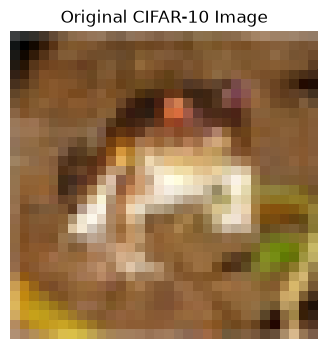

In [39]:
# Display the original image for comparison
plt.figure(figsize=(4, 4))

# Show the original RGB image
plt.imshow(one_image)

# Add title
plt.title("Original CIFAR-10 Image")

# Remove axis
plt.axis("off")

# Show image
plt.show()

# Observation

The Conv2D layer contains **16 learnable filters**, so it produces **16 feature maps** for the input image.

Each feature map shows what one learnable filter responds to. During the early layers of a CNN, filters can learn to detect simple visual patterns such as **edges, gradients, and colours**.

As we move deeper into the CNN, the network can combine these simple features to detect progressively more complex patterns such as **textures, shapes, and object parts**.

In this example:

- Input image shape: **32 × 32 × 3**
- Number of filters: **16**
- Kernel size: **3 × 3**
- Padding: **SAME**
- Output shape: **32 × 32 × 16**

Therefore, the 16 feature maps are displayed as a **4 × 4 grid**.

# A3.1 MaxPooling vs AveragePooling
## Create MaxPooling Model

In [40]:
# Check the current shape of feature_maps
print("Current feature_maps shape:", feature_maps.shape)

Current feature_maps shape: (32, 32, 16)


In [41]:
max_pool = keras.layers.MaxPooling2D(pool_size=(2, 2))

feature_maps_batch = np.expand_dims(feature_maps, axis=0)

max_pooled_maps = max_pool(feature_maps_batch)
max_pooled_maps = max_pooled_maps.numpy()
max_pooled_maps = max_pooled_maps[0]

print("Before MaxPooling:", feature_maps.shape)
print("After MaxPooling:", max_pooled_maps.shape)

Before MaxPooling: (32, 32, 16)
After MaxPooling: (16, 16, 16)


## Display MaxPooling Feature Maps

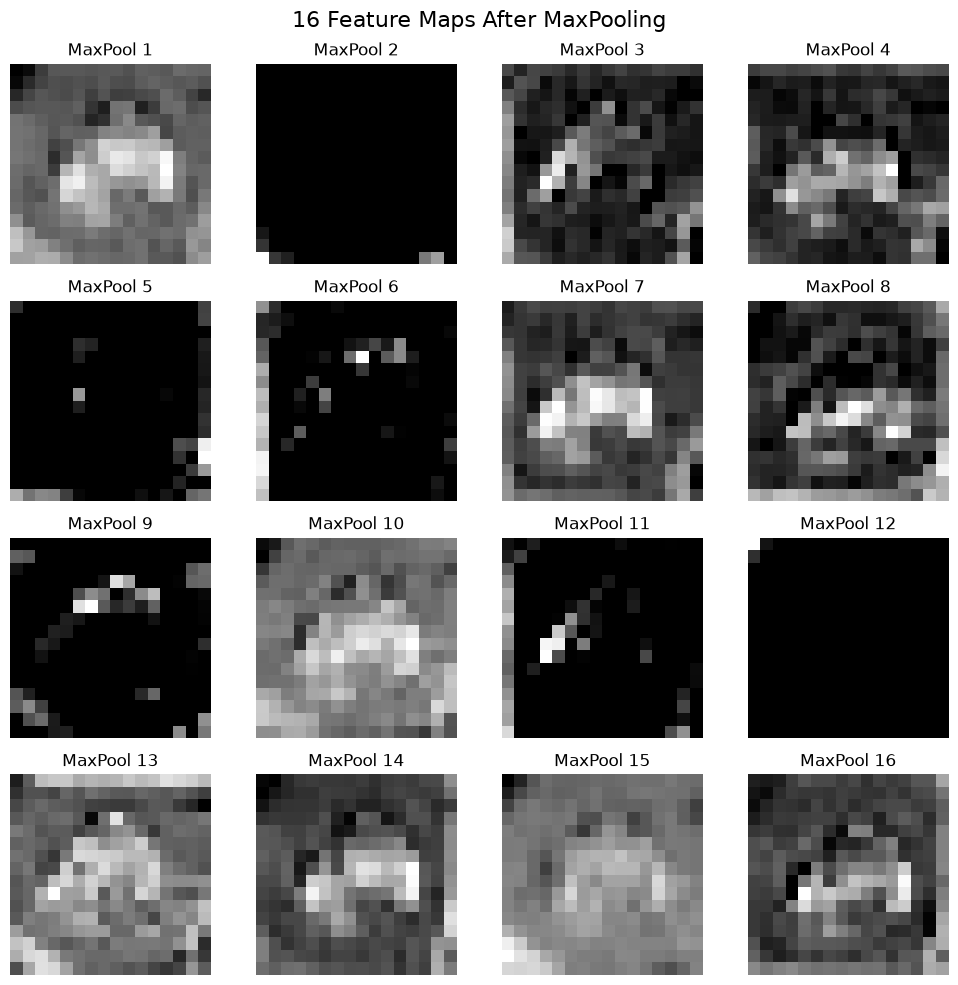

In [42]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

fig.suptitle("16 Feature Maps After MaxPooling", fontsize=16)
for i in range(16):

    # Calculate row and column
    row = i // 4
    col = i % 4

    axes[row, col].imshow(max_pooled_maps[:, :, i], cmap="gray")
    axes[row, col].set_title(f"MaxPool {i + 1}")
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Create AveragePooling Model

In [43]:
avg_pool = keras.layers.AveragePooling2D(pool_size=(2, 2))
avg_pooled_maps = avg_pool(feature_maps_batch)

avg_pooled_maps = avg_pooled_maps.numpy()
avg_pooled_maps = avg_pooled_maps[0]

print("Before AveragePooling:", feature_maps.shape)
print("After AveragePooling:", avg_pooled_maps.shape)

Before AveragePooling: (32, 32, 16)
After AveragePooling: (16, 16, 16)


## Display AveragePooling Feature Maps

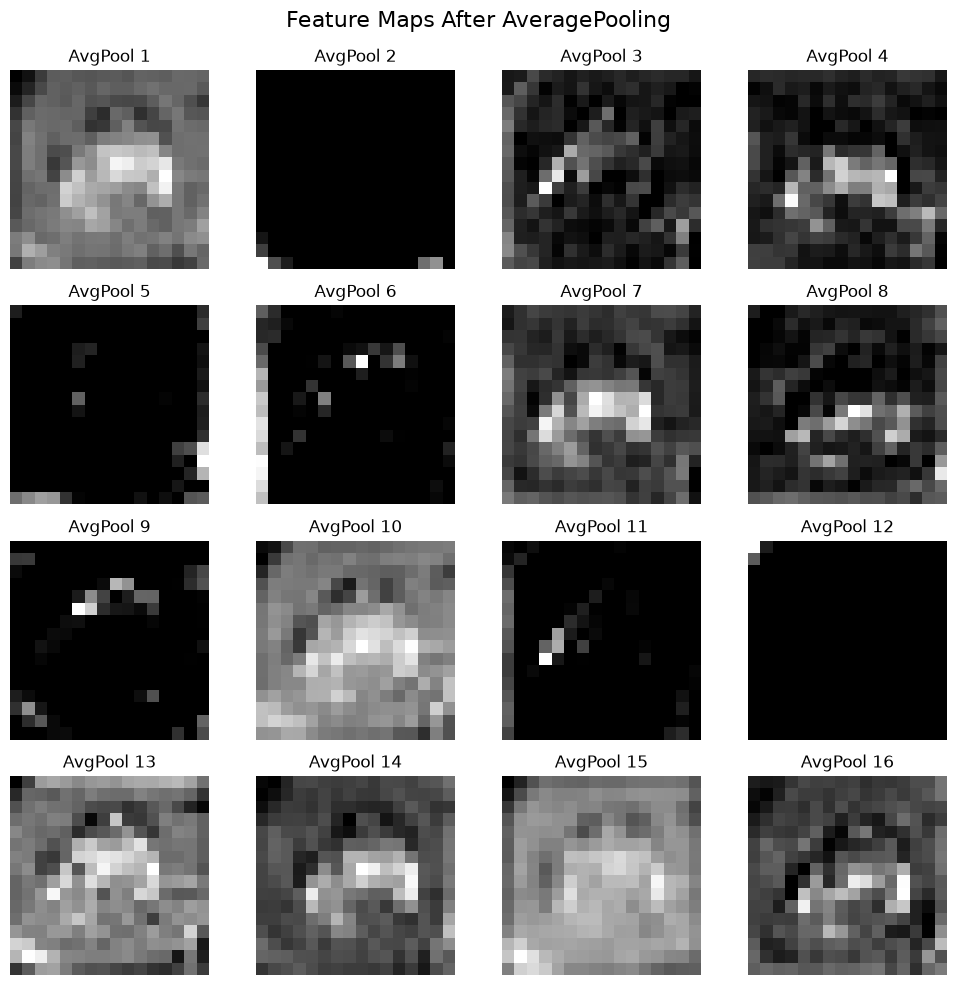

In [44]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

fig.suptitle("Feature Maps After AveragePooling", fontsize=16)

for i in range(16):

    # Calculate row and column
    row = i // 4
    col = i % 4

    axes[row, col].imshow(avg_pooled_maps[:, :, i], cmap="gray")
    axes[row, col].set_title(f"AvgPool {i + 1}")
    axes[row, col].axis("off")

plt.tight_layout()

# Keep space for main title
plt.subplots_adjust(top=0.92)
plt.show()

## A3.1 MaxPooling vs AveragePooling

### 1. MaxPooling2D

`MaxPooling2D(2,2)` takes the **maximum value** from each 2×2 patch.

It keeps the strongest activation, which usually represents the most prominent feature detected by the filter.

MaxPooling also provides a small amount of **translation invariance**, meaning the network becomes less sensitive to small changes in the exact location of a feature.

### 2. AveragePooling2D

`AveragePooling2D(2,2)` takes the **mean value** from each 2×2 patch.

It produces a smoother feature map and preserves more overall spatial information, but the resulting features are generally less sharp than MaxPooling.

### 3. GlobalAveragePooling2D

In modern CNNs, `GlobalAveragePooling2D` is often preferred over `Flatten` near the end of the network.

It averages every feature map into a single value.

For example, a feature map of `16 × 16 × 128` becomes only `128` values.

This dramatically reduces the number of parameters compared with flattening all `16 × 16 × 128` values.

### Output Comparison

| Method | Input | Output |
|---|---|---|
| Original Feature Maps | 32 × 32 × 16 | 32 × 32 × 16 |
| MaxPooling2D(2,2) | 32 × 32 × 16 | 16 × 16 × 16 |
| AveragePooling2D(2,2) | 32 × 32 × 16 | 16 × 16 × 16 |

Both pooling methods reduce the spatial dimensions from **32×32 to 16×16**.

# A3.2 Flatten Layer

In [45]:
# Create Flatten layer
flatten_layer = keras.layers.Flatten()

In [46]:
max_pooled_batch = np.expand_dims(max_pooled_maps, axis=0)

print("Shape before Flatten:", max_pooled_batch.shape)

flattened_output = flatten_layer(max_pooled_batch)
flattened_output = flattened_output.numpy()

print("Shape after Flatten:", flattened_output.shape)

Shape before Flatten: (1, 16, 16, 16)
Shape after Flatten: (1, 4096)


## Model Version

In [47]:
flatten_model = keras.Sequential([
    keras.Input(shape=(32, 32, 16)),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten()
])

flatten_model.summary()

print("Output shape after Flatten:", flatten_model.output_shape)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Output shape after Flatten: (None, 4096)


# A3.3 LeNet-5 Architecture
## Build LeNet-5 Model

In [48]:
lenet5 = keras.Sequential([

    keras.Input(shape=(32, 32, 3)),

    # First convolution layer
    keras.layers.Conv2D(
        6,
        (5, 5),
        activation="tanh"
    ),

    # First average pooling layer
    keras.layers.AveragePooling2D(
        pool_size=(2, 2)
    ),

    # Second convolution layer
    keras.layers.Conv2D(
        16,
        (5, 5),
        activation="tanh"
    ),

    # Second average pooling layer
    keras.layers.AveragePooling2D(
        pool_size=(2, 2)
    ),

    # Convert 3D feature maps into 1D vector
    keras.layers.Flatten(),

    # First fully connected layer
    keras.layers.Dense(
        120,
        activation="tanh"
    ),

    # Second fully connected layer
    keras.layers.Dense(
        84,
        activation="tanh"
    ),

    # Output layer for 10 CIFAR-10 classes
    keras.layers.Dense(
        10,
        activation="softmax"
    )
])

## Display Model Summary

In [49]:
lenet5.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

## Check Output Shapes

In [50]:
print("Final output shape:", lenet5.output_shape)

Final output shape: (None, 10)


## Understand the Shape Changes

In [51]:
# Input image size
input_size = 32

# After first 5 × 5 convolution with VALID padding
after_conv1 = input_size - 5 + 1

# After first 2 × 2 average pooling
after_pool1 = after_conv1 // 2

# After second 5 × 5 convolution
after_conv2 = after_pool1 - 5 + 1

# After second 2 × 2 average pooling
after_pool2 = after_conv2 // 2

print("Input:", input_size, "×", input_size)
print("After Conv1:", after_conv1, "×", after_conv1)
print("After Pool1:", after_pool1, "×", after_pool1)
print("After Conv2:", after_conv2, "×", after_conv2)
print("After Pool2:", after_pool2, "×", after_pool2)

flatten_size = after_pool2 * after_pool2 * 16

print("Flatten size:", flatten_size)

Input: 32 × 32
After Conv1: 28 × 28
After Pool1: 14 × 14
After Conv2: 10 × 10
After Pool2: 5 × 5
Flatten size: 400


## Manually Calculate Conv2D Parameters

In [52]:
conv1_weights = 5 * 5 * 3 * 6
conv1_bias = 6

conv1_total = conv1_weights + conv1_bias

print("Conv1 weights:", conv1_weights)
print("Conv1 bias:", conv1_bias)
print("Conv1 total parameters:", conv1_total)

Conv1 weights: 450
Conv1 bias: 6
Conv1 total parameters: 456


## Manually Calculate Conv2 Parameters

In [53]:
conv2_weights = 5 * 5 * 6 * 16
conv2_bias = 16

conv2_total = conv2_weights + conv2_bias

print("Conv2 weights:", conv2_weights)
print("Conv2 bias:", conv2_bias)
print("Conv2 total parameters:", conv2_total)

Conv2 weights: 2400
Conv2 bias: 16
Conv2 total parameters: 2416


## Check All Parameters Manually

In [54]:
# Parameters of Conv1
conv1_params = 5 * 5 * 3 * 6 + 6

#  Conv2
conv2_params = 5 * 5 * 6 * 16 + 16

#  Dense 120
dense1_params = 400 * 120 + 120

#  Dense 84
dense2_params = 120 * 84 + 84

#  Dense 10
dense3_params = 84 * 10 + 10

# Calculate total parameters
total_params = (
    conv1_params
    + conv2_params
    + dense1_params
    + dense2_params
    + dense3_params
)

print("Conv1 parameters:", conv1_params)
print("Conv2 parameters:", conv2_params)
print("Dense 120 parameters:", dense1_params)
print("Dense 84 parameters:", dense2_params)
print("Dense 10 parameters:", dense3_params)
print("Total parameters:", total_params)

Conv1 parameters: 456
Conv2 parameters: 2416
Dense 120 parameters: 48120
Dense 84 parameters: 10164
Dense 10 parameters: 850
Total parameters: 62006


# A3.4 Custom CNN Baseline for CIFAR-10
## Build Custom CNN

In [55]:
custom_cnn = keras.Sequential([

    keras.Input(shape=(32, 32, 3)),

    # First convolution layer
    keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    # Second convolution layer
    keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    # Reduce spatial dimensions
    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Third convolution layer
    keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    # Fourth convolution layer
    keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    # Reduce spatial dimensions again
    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Fifth convolution layer
    keras.layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    # Convert each feature map into one average value
    keras.layers.GlobalAveragePooling2D(),

    # Fully connected layer
    keras.layers.Dense(
        256,
        activation="relu"
    ),

    # Output layer for 10 CIFAR-10 classes
    keras.layers.Dense(
        10,
        activation="softmax"
    )
])

## Model Summary

In [56]:
custom_cnn.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

## Check Parameter Count

In [57]:
total_params = custom_cnn.count_params()

print("Total parameters:", total_params)

# Check whether the model has fewer than 2 million parameters
if total_params < 2_000_000:
    print("Parameter count is LESS than 2 million.")
else:
    print("Parameter count is NOT less than 2 million.")

Total parameters: 175018
Parameter count is LESS than 2 million.


In [58]:
# Print the output shape of the model
print("Final output shape:", custom_cnn.output_shape)

Final output shape: (None, 10)


# Observation

### Why stack two convolution layers before pooling?

The first convolution layer can learn simple visual features such as **edges, lines, gradients, and colours**.

The second convolution layer can combine these simple features to learn slightly more complex patterns such as **textures and small shapes**.

After these two convolution layers, MaxPooling reduces the spatial resolution.

This process is repeated at different feature scales. Therefore, the network can build a richer feature hierarchy while gradually reducing the spatial dimensions.

The architecture uses:

- **ReLU** for non-linear activation.
- **3×3 convolution filters** for learning local patterns.
- **MaxPooling** for spatial downsampling.
- **GlobalAveragePooling2D** to reduce the number of parameters before the Dense layers.
- **Softmax** to produce probabilities for the 10 CIFAR-10 classes.

# A4.1 Backpropagation in CNN

Backpropagation is the process used by a CNN to calculate gradients and update its learnable weights so that the loss becomes smaller.

## 1. Forward Pass

During the forward pass, the input image moves through the CNN layer by layer.

The basic flow is:

**Input Image → Convolution → Activation → Pooling → Convolution → Activation → Pooling → Flatten → Dense → Softmax → Loss**

### Step-by-step

1. The input image is given to the CNN.
2. Convolution layers apply learnable kernels to the image and produce feature maps.
3. An activation function such as ReLU introduces non-linearity.
4. Pooling layers reduce the spatial dimensions of the feature maps.
5. More convolution and pooling layers can learn increasingly complex features.
6. Flatten converts the final feature maps into a 1D vector.
7. Dense layers use these features for classification.
8. The softmax layer produces probabilities for the 10 CIFAR-10 classes.
9. A loss function, such as categorical cross-entropy, compares the predictions with the true labels.

The resulting value is called the **loss**.

---

## 2. Backward Pass

After calculating the loss, backpropagation sends gradients backwards through the network.

The purpose is to determine how much each learnable parameter contributed to the loss.

For Dense layers, the calculation of:

**∂Loss / ∂weights**

is the same basic backpropagation process used in a traditional MLP.

For convolution layers, the gradients of the loss with respect to the kernel weights must be calculated for every element of every kernel.

The upstream gradient is combined with the corresponding local input patches. This can be understood as correlating the upstream gradient with the local input regions that were used during the forward convolution.

The calculated gradients are then used by the optimizer to update the kernel weights.

---

## 3. Gradient Through MaxPooling

MaxPooling behaves differently during backpropagation.

Consider a 2×2 pooling window:

```text
[ 2   7 ]
[ 3   4 ]

# A4.2 Compile and train the CNN

In [59]:
# custom_cnn use as model_cnn
model_cnn = custom_cnn

# Model summary 
model_cnn.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

## Model Compile

In [60]:
model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


## EarlyStopping

In [61]:
es = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

print("EarlyStopping callback created.")

EarlyStopping callback created.


## ReduceLROnPlateau

In [62]:
rlrop = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)
print("ReduceLROnPlateau callback created.")

ReduceLROnPlateau callback created.


## CNN Train

In [63]:
history = model_cnn.fit(
    X_train,
    y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es, rlrop]
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 34s 45ms/step - accuracy: 0.3423 - loss: 1.7258 - val_accuracy: 0.4834 - val_loss: 1.3870 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 35s 49ms/step - accuracy: 0.5304 - loss: 1.2757 - val_accuracy: 0.5842 - val_loss: 1.1440 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 46s 56ms/step - accuracy: 0.6098 - loss: 1.0845 - val_accuracy: 0.6204 - val_loss: 1.0661 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 56ms/step - accuracy: 0.6570 - loss: 0.9620 - val_accuracy: 0.6832 - val_loss: 0.8980 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 53ms/step - accuracy: 0.6876 - loss: 0.8819 - val_accuracy: 0.6638 - val_loss: 0.9579 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 52ms/step - accuracy: 0.7140 - loss: 0.8119 - val_accuracy: 0.7038 - val_loss: 0.8363 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 52ms/step - accuracy: 0.7

In [83]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


# A4.3 Plot training curves

## Training History Values Check

In [84]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
total_epochs = len(train_loss)

epochs = range(1, total_epochs + 1)

print("Final Training Accuracy:", train_accuracy[-1])
print("Final Validation Accuracy:", val_accuracy[-1])
print("Total Epochs Completed:", total_epochs)

Final Training Accuracy: 0.9613333344459534
Final Validation Accuracy: 0.805400013923645
Total Epochs Completed: 26


## EarlyStopping aur Learning Rate Events

In [85]:
lr_reduced_epochs = []

early_stopping_epoch = total_epochs

print("ReduceLROnPlateau epochs:", lr_reduced_epochs)
print("EarlyStopping epoch:", early_stopping_epoch)

ReduceLROnPlateau epochs: []
EarlyStopping epoch: 26


## Required 1×2 Training Curves

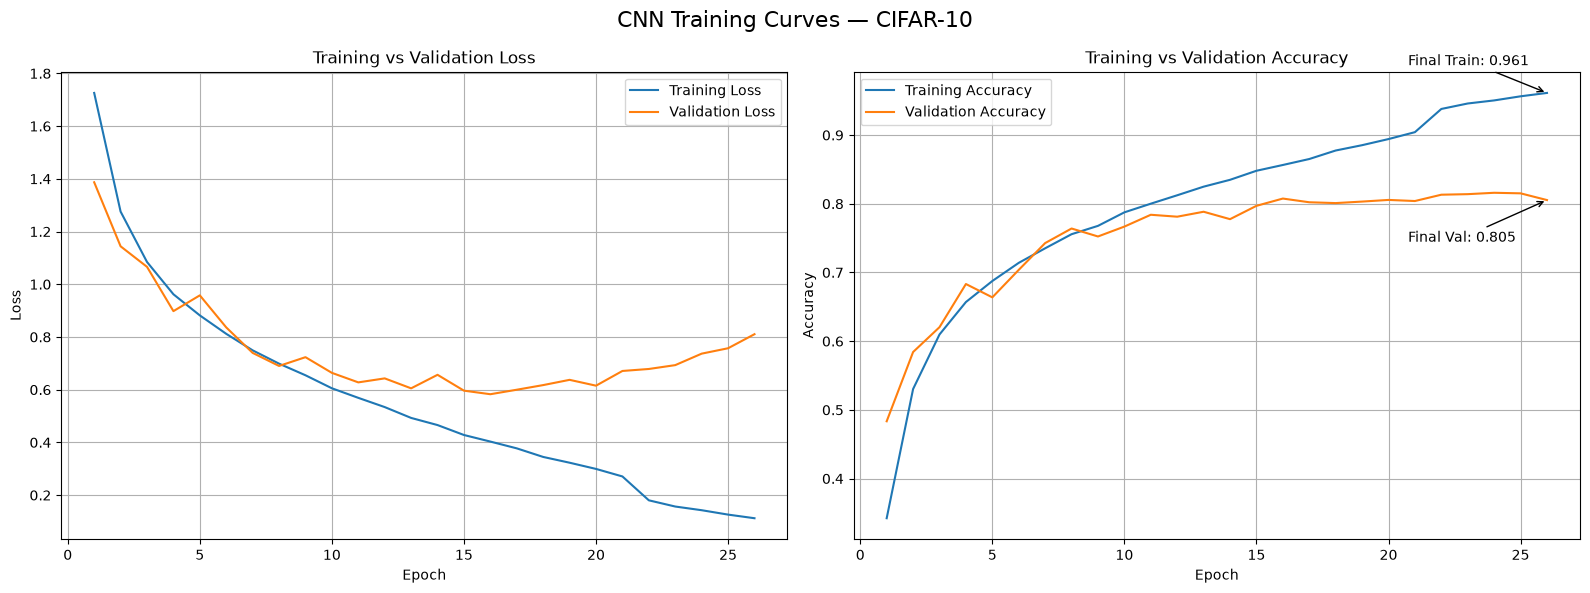

In [86]:
# Matplotlib import karna
import matplotlib.pyplot as plt

# Figure aur 1x2 subplots banana
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# -------------------------------
# Left plot: Loss
# -------------------------------

# Training loss 
axes[0].plot(
    epochs,
    train_loss,
    label="Training Loss"
)

# Validation loss plot 
axes[0].plot(
    epochs,
    val_loss,
    label="Validation Loss"
)

for epoch in lr_reduced_epochs:
    axes[0].axvline(
        x=epoch,
        linestyle="--",
        label="ReduceLROnPlateau" if epoch == lr_reduced_epochs[0] else None
    )


if early_stopping_epoch < total_epochs:
    axes[0].axvline(
        x=early_stopping_epoch,
        linestyle="--",
        label="EarlyStopping"
    )

# Loss plot labels
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


# -------------------------------
# Right plot: Accuracy
# -------------------------------

# Training accuracy 
axes[1].plot(
    epochs,
    train_accuracy,
    label="Training Accuracy"
)

# Validation accuracy plot 
axes[1].plot(
    epochs,
    val_accuracy,
    label="Validation Accuracy"
)

for epoch in lr_reduced_epochs:
    axes[1].axvline(
        x=epoch,
        linestyle="--",
        label="ReduceLROnPlateau" if epoch == lr_reduced_epochs[0] else None
    )

if early_stopping_epoch < total_epochs:
    axes[1].axvline(
        x=early_stopping_epoch,
        linestyle="--",
        label="EarlyStopping"
    )

axes[1].annotate(
    f"Final Train: {train_accuracy[-1]:.3f}",
    xy=(total_epochs, train_accuracy[-1]),
    xytext=(-100, 20),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

# Final validation accuracy annotation
axes[1].annotate(
    f"Final Val: {val_accuracy[-1]:.3f}",
    xy=(total_epochs, val_accuracy[-1]),
    xytext=(-100, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

# Accuracy plot labels
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)


# Overall figure title
fig.suptitle(
    "CNN Training Curves — CIFAR-10",
    fontsize=16
)

plt.tight_layout()

plt.show()

# A4.4 Evaluate and analyse
## Test Set Evaluation


In [87]:
test_loss, test_accuracy = model_cnn.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

# Test accuracy print karna
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.7919 - loss: 0.6214
Test Loss: 0.6214357018470764
Test Accuracy: 0.7918999791145325
Test Accuracy (%): 79.18999791145325


## Predictions

In [88]:
y_pred_probability = model_cnn.predict(X_test, verbose=1)

y_pred = np.argmax(y_pred_probability, axis=1)
y_true = y_test.flatten()

# First 10 predictions check 
print("True labels:     ", y_true[:10])
print("Predicted labels:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step
True labels:      [3 8 8 0 6 6 1 6 3 1]
Predicted labels: [3 8 8 8 6 6 1 2 3 1]


## Confusion Matrix

In [89]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[822  12  64  17   8   2   3  12  30  30]
 [ 11 897  10   4   1   1   2   1  17  56]
 [ 37   3 782  20  48  38  35  28   4   5]
 [ 20   5 108 569  52 123  55  50   4  14]
 [ 21   0  65  32 748  22  25  85   2   0]
 [  8   2  56 127  36 689  15  57   2   8]
 [  6   4  84  29  40  18 802   7   6   4]
 [ 12   0  41  19  31  21   2 870   0   4]
 [ 83  14  15   6   4   5   3   7 837  26]
 [ 25  38   5   8   2   2   1   8   8 903]]


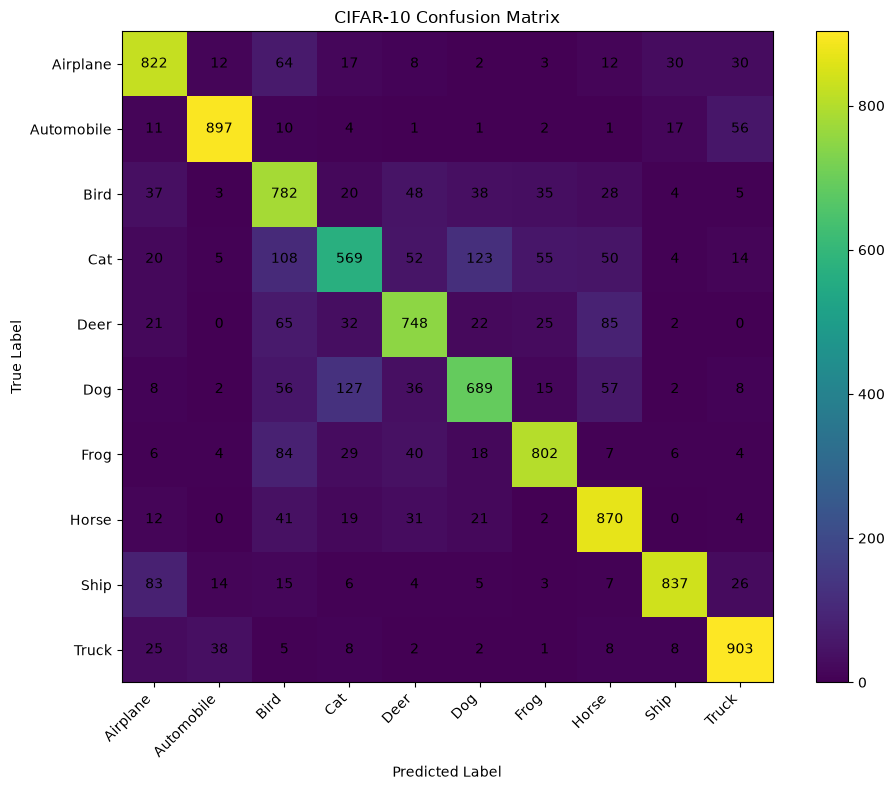

In [90]:
plt.figure(figsize=(10, 8))

plt.imshow(cm)
plt.colorbar()

plt.xticks(
    range(10),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(10),
    class_names
)

# Axis labels
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CIFAR-10 Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

## Top 3 Most-Confused Class Pairs

In [91]:
cm_without_diagonal = cm.copy()

np.fill_diagonal(cm_without_diagonal, 0)

top_indexes = np.argsort(
    cm_without_diagonal.ravel()
)[::-1][:3]

print("Top 3 Most-Confused Class Pairs:")

for index in top_indexes:
    true_class, predicted_class = np.unravel_index(
        index,
        cm_without_diagonal.shape
    )

    confusion_count = cm_without_diagonal[
        true_class,
        predicted_class
    ]

    print(
        f"{class_names[true_class]} → {class_names[predicted_class]}: "
        f"{confusion_count} images"
    )

Top 3 Most-Confused Class Pairs:
Dog → Cat: 127 images
Cat → Dog: 123 images
Cat → Bird: 108 images


## Find Misclassified Images

In [92]:
misclassified_indexes = np.where(
    y_true != y_pred
)[0]

print(
    "Total misclassified images:",
    len(misclassified_indexes)
)

selected_misclassified = misclassified_indexes[:10]

print(
    "Selected indexes:",
    selected_misclassified
)

Total misclassified images: 2081
Selected indexes: [ 3  7 22 24 25 26 29 35 37 49]


## Display 10 Misclassified Images

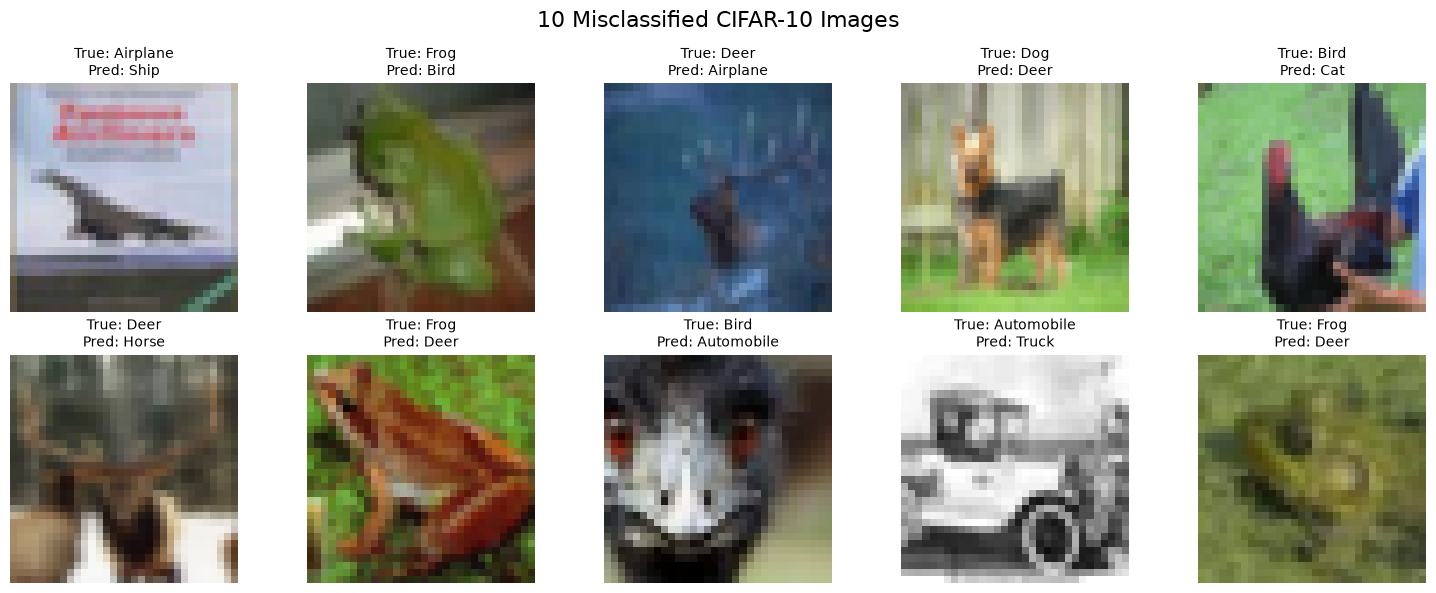

In [93]:
# 2 rows aur 5 columns ka grid banana
fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 6)
)

# Overall title
fig.suptitle(
    "10 Misclassified CIFAR-10 Images",
    fontsize=16
)

# 10 images display karna
for i, image_index in enumerate(selected_misclassified):

    # Row calculate karna
    row = i // 5

    # Column calculate karna
    col = i % 5

    # Image display karna
    axes[row, col].imshow(X_test[image_index])

    # True aur predicted class names
    true_name = class_names[y_true[image_index]]
    predicted_name = class_names[y_pred[image_index]]

    # Title mein true aur predicted labels
    axes[row, col].set_title(
        f"True: {true_name}\nPred: {predicted_name}",
        fontsize=10
    )

    # Axis remove karna
    axes[row, col].axis("off")

# Layout adjust karna
plt.tight_layout()

# Figure show karna
plt.show()

# A5.1 — Why Data Augmentation?

A CNN with around **2 million parameters** trained on only **50,000 images** can risk memorising the training data instead of learning general patterns. This problem is called **overfitting**.

**Data augmentation** artificially expands the effective training set by applying random transformations to training images, such as small rotations, shifts, flips, or zooms.

Because these transformations are applied randomly during training, the model can see a **different version of the same image in different epochs**.

For example, the same CIFAR-10 image may appear slightly shifted, flipped, or zoomed during different training epochs.

Data augmentation acts as a strong **regulariser** because it makes the model learn useful features that remain important under small changes in the image.

### Benefits of Data Augmentation

- Reduces overfitting.
- Improves the model's ability to generalise to unseen images.
- Increases the effective variety of the training data.
- Does not require collecting additional real images.
- Is especially useful for relatively small datasets with fewer than **100,000 images**.
- Is standard practice in many production computer-vision systems.

Therefore, data augmentation is an important technique for improving CNN performance when the available training dataset is limited.

# A5.2 Apply augmentation using ImageDataGenerator

In [94]:
# ImageDataGenerator import karna
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Data augmentation generator 
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)

datagen.fit(X_train)

# Message print 
print("ImageDataGenerator is ready.")

ImageDataGenerator is ready.


## One Training Image Select Karna

Image shape: (32, 32, 3)


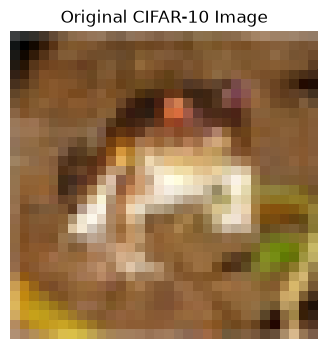

In [95]:
# Training dataset se ek image lena
img = X_train[0]

# Image ka shape check karna
print("Image shape:", img.shape)

# Original image display karna
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title("Original CIFAR-10 Image")
plt.axis("off")
plt.show()

## 9 Augmented Images Generate 

In [96]:
img_batch = img[np.newaxis, ...]

augmented_images = []

for i in range(9):

    augmented_img = next(
        datagen.flow(
            img_batch,
            batch_size=1
        )
    )[0]

    augmented_images.append(augmented_img)

print("Number of augmented images:", len(augmented_images))

print("Augmented image shape:", augmented_images[0].shape)

Number of augmented images: 9
Augmented image shape: (32, 32, 3)


## Original + 9 Augmented Images

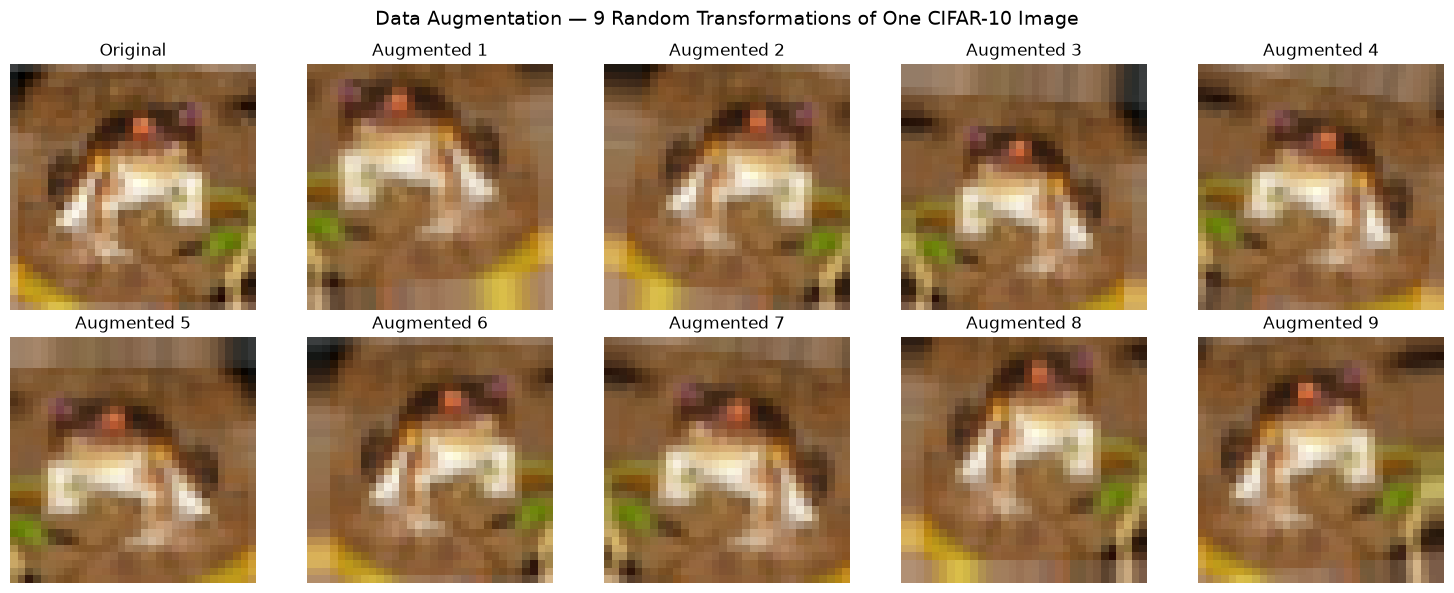

In [97]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 6)
)

# Overall figure title
fig.suptitle(
    "Data Augmentation — 9 Random Transformations of One CIFAR-10 Image",
    fontsize=14
)

axes[0, 0].imshow(img)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

for i in range(9):
    row = (i + 1) // 5
    col = (i + 1) % 5

    axes[row, col].imshow(augmented_images[i])
    axes[row, col].set_title(f"Augmented {i + 1}")
    axes[row, col].axis("off")

plt.tight_layout()

plt.show()

# A5.3 Retrain CNN with augmentation

In [98]:
model_aug = keras.Sequential([
    
    # Input layer
    keras.Input(shape=(32, 32, 3)),
    
    # First convolution block
    keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    # First pooling layer
    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),
    
    # Second convolution block
    keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    # Second pooling layer
    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),
    
    # Third convolution layer
    keras.layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    # Global Average Pooling
    keras.layers.GlobalAveragePooling2D(),
    
    # Dense layer
    keras.layers.Dense(
        256,
        activation="relu"
    ),
    
    # Output layer
    keras.layers.Dense(
        10,
        activation="softmax"
    )
])

# Model summary
model_aug.summary()

# Total parameters print karna
print("Total parameters:", model_aug.count_params())

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 175018


## Compile Model

In [99]:
model_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Compile confirmation
print("Augmented CNN compiled successfully.")

Augmented CNN compiled successfully.


## Callbacks

In [100]:
# EarlyStopping callback
es_aug = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# ReduceLROnPlateau callback
rlrop_aug = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Confirmation
print("Callbacks created.")

Callbacks created.


## Augmented Data Generator

In [101]:
train_generator = datagen.flow(
    X_train,
    y_train_ohe,
    batch_size=64
)

sample_images, sample_labels = next(train_generator)

print("Batch images shape:", sample_images.shape)
print("Batch labels shape:", sample_labels.shape)

Batch images shape: (64, 32, 32, 3)
Batch labels shape: (64, 10)


## Train CNN with Augmentation

In [102]:
# Training data 10% validation size calculate 
validation_size = int(len(X_train) * 0.1)

# Last 10% validation data 
X_val_aug = X_train[-validation_size:]
y_val_aug = y_train_ohe[-validation_size:]

# First 90% actual augmented 
X_train_aug = X_train[:-validation_size]
y_train_aug = y_train_ohe[:-validation_size]

# Shapes check karna
print("Augmented training images:", X_train_aug.shape)
print("Augmented training labels:", y_train_aug.shape)

print("Validation images:", X_val_aug.shape)
print("Validation labels:", y_val_aug.shape)

Augmented training images: (45000, 32, 32, 3)
Augmented training labels: (45000, 10)
Validation images: (5000, 32, 32, 3)
Validation labels: (5000, 10)


In [103]:
# only training portion for augmentation generator 
train_generator_aug = datagen.flow(
    X_train_aug,
    y_train_aug,
    batch_size=64,
    shuffle=True
)

history_aug = model_aug.fit(
    train_generator_aug,
    epochs=100,
    validation_data=(X_val_aug, y_val_aug),
    callbacks=[es_aug, rlrop_aug]
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 88s 119ms/step - accuracy: 0.3226 - loss: 1.7834 - val_accuracy: 0.4362 - val_loss: 1.5250 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 117ms/step - accuracy: 0.4698 - loss: 1.4346 - val_accuracy: 0.5076 - val_loss: 1.3474 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 76s 108ms/step - accuracy: 0.5304 - loss: 1.2833 - val_accuracy: 0.5738 - val_loss: 1.1764 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 79s 111ms/step - accuracy: 0.5749 - loss: 1.1744 - val_accuracy: 0.5992 - val_loss: 1.1618 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 87s 124ms/step - accuracy: 0.6068 - loss: 1.0942 - val_accuracy: 0.6388 - val_loss: 1.0431 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 83s 117ms/step - accuracy: 0.6374 - loss: 1.0172 - val_accuracy: 0.6552 - val_loss: 1.0293 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 83s 117ms/step - accura

## Compare Training Curves

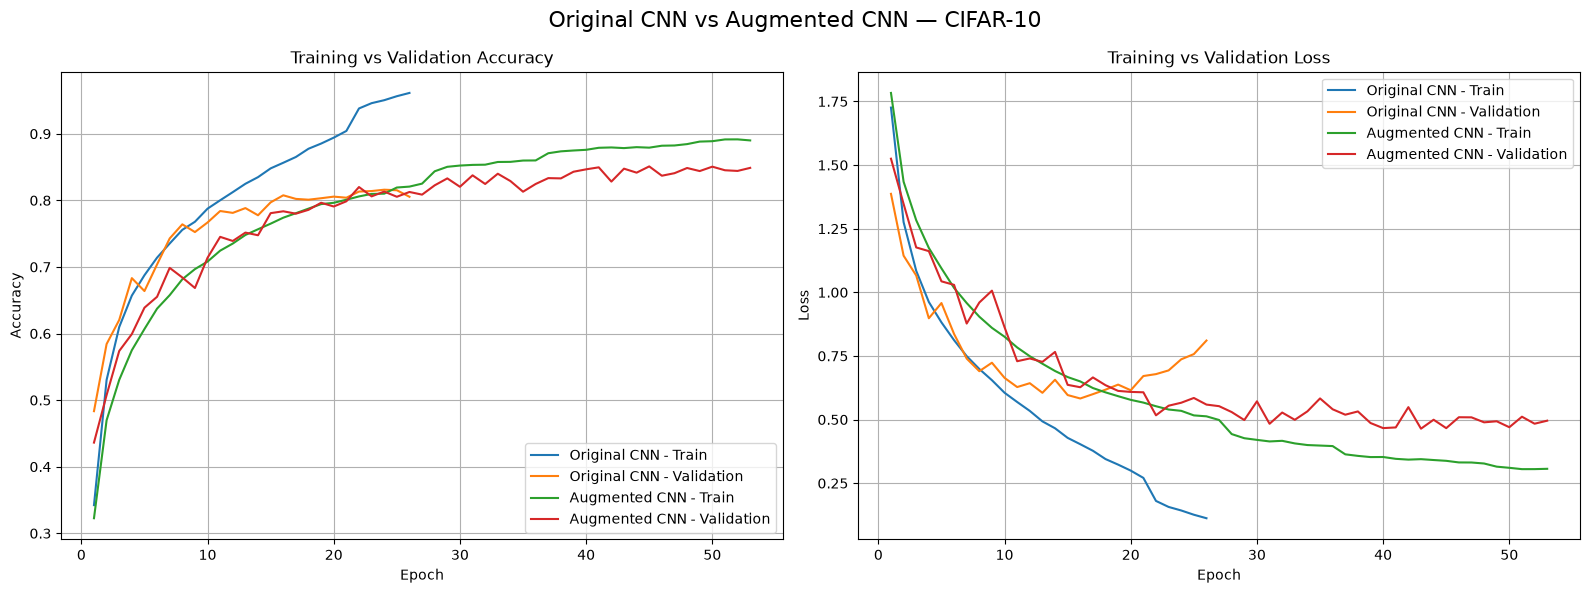

In [104]:
# Original CNN history
original_train_accuracy = history.history["accuracy"]
original_val_accuracy = history.history["val_accuracy"]

# Augmented CNN history
aug_train_accuracy = history_aug.history["accuracy"]
aug_val_accuracy = history_aug.history["val_accuracy"]

# Original CNN epochs
epochs_original = range(1, len(original_train_accuracy) + 1)
epochs_aug = range(1, len(aug_train_accuracy) + 1)

# 1x2 figure banana
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

# Accuracy comparison


# Original training accuracy
axes[0].plot(
    epochs_original,
    original_train_accuracy,
    label="Original CNN - Train"
)

# Original validation accuracy
axes[0].plot(
    epochs_original,
    original_val_accuracy,
    label="Original CNN - Validation"
)

# Augmented training accuracy
axes[0].plot(
    epochs_aug,
    aug_train_accuracy,
    label="Augmented CNN - Train"
)

# Augmented validation accuracy
axes[0].plot(
    epochs_aug,
    aug_val_accuracy,
    label="Augmented CNN - Validation"
)

# Accuracy labels
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

               # Loss comparison

# Original CNN loss
axes[1].plot(
    epochs_original,
    history.history["loss"],
    label="Original CNN - Train"
)

axes[1].plot(
    epochs_original,
    history.history["val_loss"],
    label="Original CNN - Validation"
)

# Augmented CNN loss
axes[1].plot(
    epochs_aug,
    history_aug.history["loss"],
    label="Augmented CNN - Train"
)

axes[1].plot(
    epochs_aug,
    history_aug.history["val_loss"],
    label="Augmented CNN - Validation"
)

# Loss labels
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

# Overall title
fig.suptitle(
    "Original CNN vs Augmented CNN — CIFAR-10",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Accuracy Comparison

In [105]:
original_final_val = original_val_accuracy[-1]

aug_final_val = aug_val_accuracy[-1]

print(
    "Original CNN final validation accuracy:",
    original_final_val
)

print(
    "Augmented CNN final validation accuracy:",
    aug_final_val
)

difference = aug_final_val - original_final_val

print(
    "Validation accuracy difference:",
    difference
)

Original CNN final validation accuracy: 0.805400013923645
Augmented CNN final validation accuracy: 0.848800003528595
Validation accuracy difference: 0.04339998960494995


# A5.4 Modern augmentation with Keras layers
## Modern Data Augmentation Layers

In [106]:
from tensorflow import keras

data_augmentation = keras.Sequential([
    
    keras.layers.RandomFlip("horizontal"),
    
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    
    keras.layers.RandomTranslation(
        0.1,
        0.1
    )
])

data_augmentation.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Augmentation Check

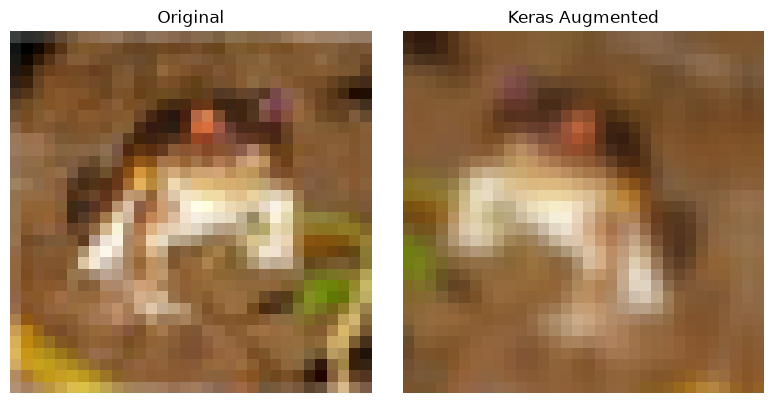

In [107]:
sample_image = X_train[0]

sample_image_batch = np.expand_dims(
    sample_image,
    axis=0
)

augmented_sample = data_augmentation(
    sample_image_batch,
    training=True
)

# Batch dimension remove karna
augmented_sample = augmented_sample[0].numpy()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8, 4)
)

# Original image
axes[0].imshow(sample_image)
axes[0].set_title("Original")
axes[0].axis("off")

# Augmented image
axes[1].imshow(augmented_sample)
axes[1].set_title("Keras Augmented")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Build Modern Augmented CNN

In [ ]:
model_keras_aug = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    # Data augmentation layers
    data_augmentation,

    # First convolution block
    keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Third convolution layer
    keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),

    # Global Average Pooling
    keras.layers.GlobalAveragePooling2D(),

    # Dense layer
    keras.layers.Dense(256, activation="relu"),

    # CIFAR-10 10 classes
    keras.layers.Dense(10, activation="softmax")
])

# Model summary
model_keras_aug.summary()

print("Total parameters:", model_keras_aug.count_params())

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_10 (Sequential)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 175018


## compile model

In [111]:
model_keras_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modern Keras augmentation model compiled successfully.")

Modern Keras augmentation model compiled successfully.


## Callbacks

In [112]:
# EarlyStopping callback
es_keras = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# ReduceLROnPlateau callback
rlrop_keras = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

## Train Modern Augmented CNN

In [113]:
history_keras_aug = model_keras_aug.fit(
    X_train_aug,
    y_train_aug,
    epochs=100,
    batch_size=64,
    validation_data=(X_val_aug, y_val_aug),
    callbacks=[es_keras, rlrop_keras]
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 38ms/step - accuracy: 0.2810 - loss: 1.9119 - val_accuracy: 0.3680 - val_loss: 1.7429 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.4186 - loss: 1.5757 - val_accuracy: 0.4322 - val_loss: 1.5511 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.4863 - loss: 1.4024 - val_accuracy: 0.5126 - val_loss: 1.3341 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.5269 - loss: 1.3044 - val_accuracy: 0.5390 - val_loss: 1.3312 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.5619 - loss: 1.2195 - val_accuracy: 0.5480 - val_loss: 1.3062 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.5840 - loss: 1.1624 - val_accuracy: 0.5610 - val_loss: 1.3183 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.6

## Test Accuracy Comparison

In [115]:
idg_test_loss, idg_test_accuracy = model_aug.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

keras_test_loss, keras_test_accuracy = model_keras_aug.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print("ImageDataGenerator Test Accuracy:",
      idg_test_accuracy)

print("Modern Keras Augmentation Test Accuracy:",
      keras_test_accuracy)

print(
    "ImageDataGenerator Test Accuracy (%):",
    idg_test_accuracy * 100
)

print(
    "Modern Keras Augmentation Test Accuracy (%):",
    keras_test_accuracy * 100
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8489 - loss: 0.4923
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7867 - loss: 0.7065
ImageDataGenerator Test Accuracy: 0.8489000201225281
Modern Keras Augmentation Test Accuracy: 0.7867000102996826
ImageDataGenerator Test Accuracy (%): 84.89000201225281
Modern Keras Augmentation Test Accuracy (%): 78.67000102996826


## Accuracy Comparison

In [116]:
if keras_test_accuracy > idg_test_accuracy:
    print("Modern Keras augmentation performed better.")
elif keras_test_accuracy < idg_test_accuracy:
    print("ImageDataGenerator performed better.")
else:
    print("Both approaches achieved the same test accuracy.")

ImageDataGenerator performed better.


# A6: Transfer Learning — Feature Extraction & Fine-Tuning

# Why Transfer Learning?

Training a deep CNN from scratch on CIFAR-10 can take several hours and requires a substantial amount of training data. **Transfer Learning** provides a faster alternative by using a model that has already been trained on a much larger dataset.

For example, **MobileNetV2** is available with pre-trained weights from ImageNet, a large dataset containing approximately 14 million images across 1,000 classes.

The pre-trained model has already learned a hierarchy of visual features, such as:

- **Edges:** Basic lines and boundaries in images.
- **Textures:** Patterns such as fur, grass, and fabric.
- **Shapes:** Simple and complex object outlines.
- **Object parts:** Features such as wheels, faces, and wings.

These features are useful across many computer-vision tasks. Therefore, instead of learning everything from the beginning, we can adapt the pre-trained model to classify the 10 CIFAR-10 classes.

## Two Strategies of Transfer Learning

### 1. Feature Extraction

In feature extraction, all pre-trained layers of the base model are **frozen**, meaning their weights are not updated during training.

A new classification head is added to the base model and trained on the CIFAR-10 dataset.

**Advantages:**
- Faster training, often taking only a few minutes.
- Requires fewer computational resources.
- Reduces the risk of overfitting when the dataset is small.

**Limitation:**
- The pre-trained features cannot adapt to the new dataset, which may limit accuracy.

### 2. Fine-Tuning

In fine-tuning, some of the top layers of the pre-trained model are **unfrozen** and trained along with the new classification head.

A very low learning rate is used to make small, careful updates to the pre-trained weights.

**Advantages:**
- Allows the model to adapt its learned features to CIFAR-10.
- Can achieve higher accuracy than feature extraction.

**Limitations:**
- Requires more training time and computational resources.
- May overfit if too many layers are unfrozen or the learning rate is too high.

## Feature Extraction vs Fine-Tuning

| Feature | Feature Extraction | Fine-Tuning |
|---|---|---|
| Pre-trained weights | All frozen | Some top layers unfrozen |
| Trainable parameters | Classification head only | Head and selected base layers |
| Training speed | Faster | Slower |
| Computational cost | Lower | Higher |
| Adaptation to CIFAR-10 | Limited | Greater |
| Potential accuracy | Good baseline | Often higher |

## Conclusion

Transfer Learning reuses knowledge learned from a large dataset and applies it to a new task.

**Feature Extraction** is a fast and efficient starting point, while **Fine-Tuning** allows the pre-trained model to adapt further to CIFAR-10 and may improve classification accuracy.

# A6.2	Feature Extraction with MobileNetV2
## Training Images Resize Karna

In [117]:
X_train_r = tf.image.resize(X_train, (96, 96))

X_test_r = tf.image.resize(X_test, (96, 96))

print("Resized training images:", X_train_r.shape)
print("Resized test images:", X_test_r.shape)

Resized training images: (50000, 96, 96, 3)
Resized test images: (10000, 96, 96, 3)


## MobileNetV2 Load Karna

In [118]:
# ImageNet pre-trained MobileNetV2 load 
base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_1.00_96"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16      │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 48, 48,    │        864 │ input_layer_16[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 48, 48,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 48, 48,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 48, 48,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 48, 48,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 48, 48,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 49, 49,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 24, 24,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 24, 24,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

## Build Feature Extraction Model

In [119]:
inputs = keras.Input(shape=(96, 96, 3))

x = keras.layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(inputs)

x = base_model(x, training=False)

x = keras.layers.GlobalAveragePooling2D()(x)

x = keras.layers.Dense(
    128,
    activation="relu"
)(x)

outputs = keras.layers.Dense(
    10,
    activation="softmax"
)(x)

model_transfer = keras.Model(
    inputs=inputs,
    outputs=outputs
)

model_transfer.summary()

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Total aur Trainable Parameters

In [120]:
total_params = model_transfer.count_params()

trainable_params = sum(
    tf.size(variable).numpy()
    for variable in model_transfer.trainable_weights
)

non_trainable_params = total_params - trainable_params

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

Total parameters: 2423242
Trainable parameters: 165258
Non-trainable parameters: 2257984


# A6.3	Train feature extraction model

In [121]:
model_fe = model_transfer

model_fe.summary()

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Compile Model

In [122]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("Feature extraction model compiled successfully.")

Feature extraction model compiled successfully.


## Train Model

In [123]:
history_fe = model_fe.fit(
    X_train_r,
    y_train_ohe,
    epochs=20,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 138s 191ms/step - accuracy: 0.8241 - loss: 0.5114 - val_accuracy: 0.8570 - val_loss: 0.4136
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 146s 208ms/step - accuracy: 0.8732 - loss: 0.3631 - val_accuracy: 0.8602 - val_loss: 0.4034
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 141s 200ms/step - accuracy: 0.8921 - loss: 0.3102 - val_accuracy: 0.8702 - val_loss: 0.3904
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 145s 205ms/step - accuracy: 0.9072 - loss: 0.2658 - val_accuracy: 0.8716 - val_loss: 0.3811
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 142s 201ms/step - accuracy: 0.9216 - loss: 0.2240 - val_accuracy: 0.8722 - val_loss: 0.3982
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 120s 171ms/step - accuracy: 0.9330 - loss: 0.1911 - val_accuracy: 0.8728 - val_loss: 0.3985
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 135s 192ms/step - accuracy: 0.9463 - loss: 0.1564 - val_accuracy: 0.8690 - val_loss: 0.4126
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 148s 210ms/step - accuracy: 0.9582 -

## Evaluate on Test Data

In [124]:
test_loss_fe, test_accuracy_fe = model_fe.evaluate(
    X_test_r,
    y_test_ohe,
    verbose=1
)

print("Feature Extraction Test Loss:", test_loss_fe)
print("Feature Extraction Test Accuracy:", test_accuracy_fe)
print("Feature Extraction Test Accuracy (%):", test_accuracy_fe * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 96ms/step - accuracy: 0.8527 - loss: 0.9475
Feature Extraction Test Loss: 0.9475210905075073
Feature Extraction Test Accuracy: 0.8526999950408936
Feature Extraction Test Accuracy (%): 85.26999950408936


## Scratch CNN with Compare

In [125]:
test_loss_scratch, test_accuracy_scratch = model_cnn.evaluate(
    X_test,
    y_test_ohe,
    verbose=0
)

print("Scratch CNN Test Accuracy (%):", test_accuracy_scratch * 100)
print("MobileNetV2 Feature Extraction Accuracy (%):", test_accuracy_fe * 100)

accuracy_difference = (
    test_accuracy_fe - test_accuracy_scratch
) * 100

print("Accuracy Difference (percentage points):", accuracy_difference)

Scratch CNN Test Accuracy (%): 79.18999791145325
MobileNetV2 Feature Extraction Accuracy (%): 85.26999950408936
Accuracy Difference (percentage points): 6.080001592636108


# A6.4	Fine-Tuning
## Unfreeze Top 30 Layers

In [126]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

trainable_layers = sum(
    1 for layer in base_model.layers if layer.trainable
)

print("Total MobileNetV2 layers:", len(base_model.layers))
print("Trainable MobileNetV2 layers:", trainable_layers)

print("Trainable parameters:", sum(
    tf.size(variable).numpy()
    for variable in model_fe.trainable_weights
))

Total MobileNetV2 layers: 154
Trainable MobileNetV2 layers: 30
Trainable parameters: 1691658


## Recompile with a Low Learning Rate

In [127]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


## Fine-Tune the Model

In [128]:
es_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

rlrop_ft = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

history_ft = model_fe.fit(
    X_train_r,
    y_train_ohe,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_ft, rlrop_ft]
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 198s 136ms/step - accuracy: 0.8128 - loss: 1.4734 - val_accuracy: 0.8552 - val_loss: 1.1139 - learning_rate: 1.0000e-05
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 177s 126ms/step - accuracy: 0.8714 - loss: 0.7682 - val_accuracy: 0.8552 - val_loss: 1.0634 - learning_rate: 1.0000e-05
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 252s 179ms/step - accuracy: 0.8905 - loss: 0.5398 - val_accuracy: 0.8564 - val_loss: 0.9984 - learning_rate: 1.0000e-05
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 294s 209ms/step - accuracy: 0.9079 - loss: 0.3960 - val_accuracy: 0.8552 - val_loss: 0.9533 - learning_rate: 1.0000e-05
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 298s 211ms/step - accuracy: 0.9208 - loss: 0.3082 - val_accuracy: 0.8592 - val_loss: 0.9011 - learning_rate: 1.0000e-05
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 287s 204ms/step - accuracy: 0.9305 - loss: 0.2509 - val_accuracy: 0.8624 - val_loss: 0.8512 - learning_rate: 1.0000e-05
Epoch 7/10
1407/1407 ━━━━━━━

## Plot Feature Extraction + Fine-Tuning Curves

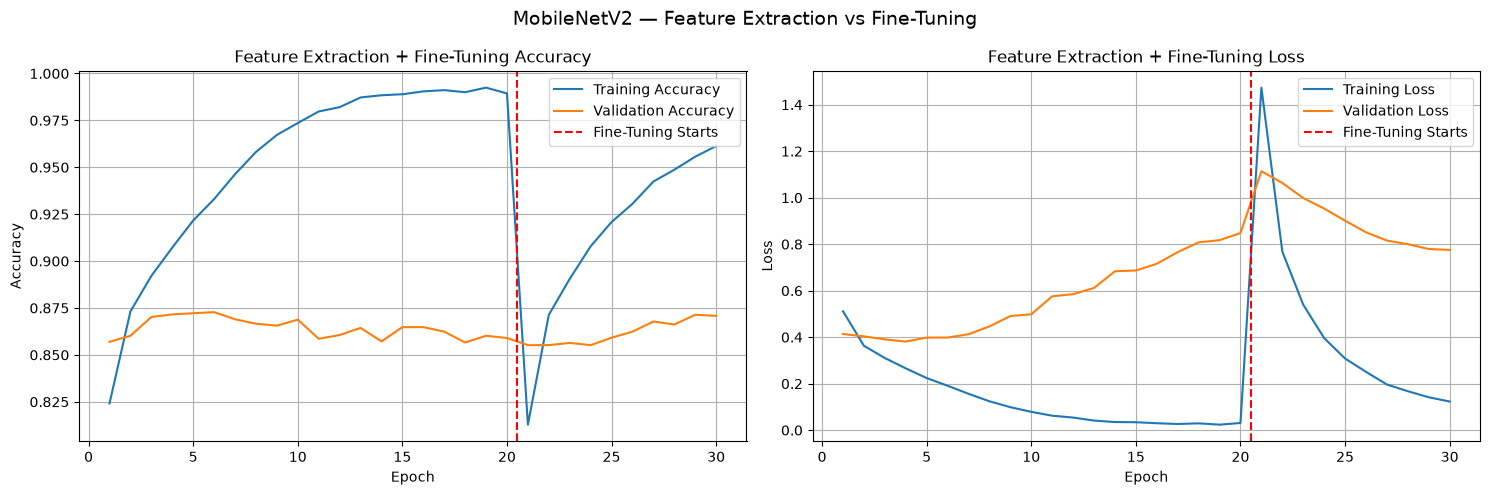

In [129]:
fe_train_acc = history_fe.history["accuracy"]
fe_val_acc = history_fe.history["val_accuracy"]

ft_train_acc = history_ft.history["accuracy"]
ft_val_acc = history_ft.history["val_accuracy"]

all_train_acc = fe_train_acc + ft_train_acc
all_val_acc = fe_val_acc + ft_val_acc

all_train_loss = history_fe.history["loss"] + history_ft.history["loss"]
all_val_loss = history_fe.history["val_loss"] + history_ft.history["val_loss"]

total_epochs = len(all_train_acc)
fine_tuning_start = len(fe_train_acc) + 0.5

epochs = range(1, total_epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy plot
axes[0].plot(epochs, all_train_acc, label="Training Accuracy")
axes[0].plot(epochs, all_val_acc, label="Validation Accuracy")

# Fine-tuning start mark 
axes[0].axvline(
    x=fine_tuning_start,
    color="red",
    linestyle="--",
    label="Fine-Tuning Starts"
)

axes[0].set_title("Feature Extraction + Fine-Tuning Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss plot
axes[1].plot(epochs, all_train_loss, label="Training Loss")
axes[1].plot(epochs, all_val_loss, label="Validation Loss")

# Fine-tuning start mark 
axes[1].axvline(
    x=fine_tuning_start,
    color="red",
    linestyle="--",
    label="Fine-Tuning Starts"
)

axes[1].set_title("Feature Extraction + Fine-Tuning Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

# Overall title
fig.suptitle("MobileNetV2 — Feature Extraction vs Fine-Tuning", fontsize=14)

plt.tight_layout()
plt.show()

## Compare Test Accuracy

In [130]:
test_loss_ft, test_accuracy_ft = model_fe.evaluate(
    X_test_r,
    y_test_ohe,
    verbose=1
)

print("Feature Extraction Test Accuracy (%):", test_accuracy_fe * 100)
print("Fine-Tuned Test Accuracy (%):", test_accuracy_ft * 100)

print(
    "Change in test accuracy (percentage points):",
    (test_accuracy_ft - test_accuracy_fe) * 100
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 125ms/step - accuracy: 0.8651 - loss: 0.8513
Feature Extraction Test Accuracy (%): 85.26999950408936
Fine-Tuned Test Accuracy (%): 86.51000261306763
Change in test accuracy (percentage points): 1.2400031089782715


# A6.5	Full results comparison table

In [134]:

# Compile LeNet-5
lenet5.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Compile CNN + ImageDataGenerator
model_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Compile CNN + Keras Augmentation
model_keras_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("All three models compiled successfully!")


All three models compiled successfully!


In [135]:

# 1. LeNet-5 test accuracy
test_loss_lenet, test_accuracy_lenet = lenet5.evaluate(
    X_test, y_test_ohe, verbose=0
)

# 2. CNN + ImageDataGenerator test accuracy
test_loss_aug, test_accuracy_aug = model_aug.evaluate(
    X_test, y_test_ohe, verbose=0
)

# 3. CNN + Keras Augmentation Layers test accuracy
test_loss_keras_aug, test_accuracy_keras_aug = model_keras_aug.evaluate(
    X_test, y_test_ohe, verbose=0
)

# Print all three accuracies
print("LeNet-5 Accuracy:", test_accuracy_lenet)
print("CNN + ImageDataGenerator Accuracy:", test_accuracy_aug)
print("CNN + Keras Augmentation Accuracy:", test_accuracy_keras_aug)


LeNet-5 Accuracy: 0.09650000184774399
CNN + ImageDataGenerator Accuracy: 0.8489000201225281
CNN + Keras Augmentation Accuracy: 0.7867000102996826


# A6.6	Non-linear architecture — Residual connection
## Build a Residual Block

In [ ]:
inputs = keras.Input(shape=(32, 32, 64), name="residual_input")

# Shortcut path: 1x1 convolution
shortcut = keras.layers.Conv2D(
    64,
    kernel_size=(1, 1),
    padding="same",
    name="shortcut_conv"
)(inputs)

# Main path: first 3x3 convolution with ReLU
x = keras.layers.Conv2D(
    64,
    kernel_size=(3, 3),
    activation="relu",
    padding="same",
    name="main_conv1"
)(inputs)

# Main path: second 3x3 convolution with ReLU
x = keras.layers.Conv2D(
    64,
    kernel_size=(3, 3),
    activation="relu",
    padding="same",
    name="main_conv2"
)(x)

# Add the main path and shortcut path
x = keras.layers.Add(name="skip_add")([x, shortcut])

# Apply ReLU after addition
outputs = keras.layers.Activation("relu", name="output_relu")(x)

# Build the Functional API model
residual_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="minimal_residual_block"
)

# Display the model architecture
residual_model.summary()


Model: "minimal_residual_block"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ residual_input      │ (None, 32, 32,    │          0 │ -                 │
│ (InputLayer)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ main_conv1 (Conv2D) │ (None, 32, 32,    │     36,928 │ residual_input[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ main_conv2 (Conv2D) │ (None, 32, 32,    │     36,928 │ main_conv1[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shortcut_conv       │ (None, 32, 32,    │      4,160 │ residual_input[0… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_add (Add)      │ (None, 32, 32,    │          0 │ main_conv2[0][0], │
│                     │ 64)               │            │ shortcut_conv[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_relu         │ (None, 32, 32,    │          0 │ skip_add[0][0]    │
│ (Activation)        │ 64)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,016 (304.75 KB)

 Trainable params: 78,016 (304.75 KB)

 Non-trainable params: 0 (0.00 B)

## Output shape

In [ ]:
# Test the model with a sample input
sample_input = tf.random.normal((1, 32, 32, 64))
sample_output = residual_model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)

Input shape: (1, 32, 32, 64)
Output shape: (1, 32, 32, 64)


# — Non-Linear Architecture: Residual Connection

A residual block is a non-sequential CNN architecture that introduces a **skip connection**. The input travels through two paths: a shortcut path containing a 1×1 convolution and a main path containing two 3×3 convolution layers. The outputs are added together, followed by a ReLU activation.

**Why are residual connections useful?**

- They allow information and gradients to travel through shortcut paths during backpropagation.
- They help reduce the vanishing-gradient and degradation problems in very deep neural networks.
- They make it easier to train deeper architectures.
- The residual learning concept is the core innovation of **ResNet**, introduced by He et al. in 2016.

Unlike a purely sequential CNN, a Functional API model supports multiple paths and layer connections. Residual connections help gradient flow, although they do not guarantee that the vanishing-gradient problem will be completely eliminated.